# 11 - DEM Processing

**GPU-Accelerated Terrain Analysis for GLOF Risk Assessment**

## Objectives
- Mosaic multi-tile DEMs for each study area
- Reproject raw DEM (WGS-84) to local UTM projection
- Calculate terrain derivatives used by downstream notebooks:
  - **Slope** and **Aspect** (orientation of steepest descent)
  - **Curvature** (plan + profile)
  - **TRI** (Terrain Ruggedness Index)
  - **Roughness** (local relief)
  - **VRM** (Vector Ruggedness Measure)
  - **TWI** (Topographic Wetness Index)
- Generate terrain summary statistics per area

## Methodology
1. **Mosaic**: merge multiple NASADEM tiles with rasterio
2. **Reproject**: WGS-84 → UTM (per-area EPSG from config)
3. **Terrain analysis**: GPU-accelerated (CuPy/Numba) with CPU fallback
4. **TWI**: D8 flow accumulation → ln(A / tan(slope))

## Key Outputs
- `data/interim/dem/{area}_dem_utm.tif` ← **required by notebook 12**
- `data/interim/terrain/{area}/slope.tif`
- `data/interim/terrain/{area}/aspect.tif`
- `data/interim/terrain/{area}/curvature.tif`
- `data/interim/terrain/{area}/tri.tif`
- `data/interim/terrain/{area}/roughness.tif`
- `data/interim/terrain/{area}/vrm.tif`
- `data/interim/terrain/{area}/twi.tif`
- `data/processed/terrain_summary.csv`

In [1]:
# --- GLOF PROJECT STANDARD SETUP ---
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
try:
    import geopandas as gpd
except ImportError:
    pass

# ── Rutas ──────────────────────────────────────────────────────────────────
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root))

# Recarga de módulos de src (opcional para desarrollo)
import importlib
import src.gpu_utils
importlib.reload(src.gpu_utils)

# Fix PROJ: usar proj.db de rasterio (v1.6) en vez del de pyproj (v1.4)
# El pyproj bundled tiene VERSION.MINOR=4 pero rasterio necesita >=6
if 'PROJ_LIB' in os.environ:
    del os.environ['PROJ_LIB']
try:
    import rasterio as _rio
    _proj_data = Path(_rio.__file__).parent / 'proj_data'
    if _proj_data.exists():
        os.environ['PROJ_LIB'] = str(_proj_data)
    del _rio, _proj_data
except Exception:
    pass

from src.gpu_utils import GPUConfig, gpu_array, cpu_array, clear_gpu_memory
gpu_config = GPUConfig()
print(gpu_config)

GPU_AVAILABLE = gpu_config.has_gpu
CUPY_AVAILABLE = gpu_config.cupy_available

GPU CONFIGURATION
GPU Available: True
Device: NVIDIA GeForce RTX 3050 Laptop GPU
Device Count: 1
Memory Total: 4.0 GB
Memory Free: 4.0 GB
CUDA Version: None

Library Support:
  - CuPy:         yes
  - PyTorch CUDA: no
  - Numba CUDA:   yes


In [2]:
# =============================================================================
# IMPORTS
# =============================================================================
import rasterio
from rasterio.merge import merge
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.crs import CRS
import scipy.ndimage as ndimage
from scipy.ndimage import uniform_filter
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time
import json

from config_expanded_study_areas import EXPANDED_STUDY_AREAS

print("Imports OK")

Imports OK


In [3]:
# =============================================================================
# CONFIGURATION
# =============================================================================
DATA_DIR    = project_root / 'data'
RAW_DIR     = DATA_DIR / 'raw'
INTERIM_DIR = DATA_DIR / 'interim'
PROCESSED_DIR = DATA_DIR / 'processed'

# Detect study areas from DEM directory
dem_raw_dir = RAW_DIR / 'dem'
if dem_raw_dir.exists():
    STUDY_AREAS = sorted([d.name for d in dem_raw_dir.iterdir() if d.is_dir()])
    print(f"Detected {len(STUDY_AREAS)} study areas with DEM data:")
    for a in STUDY_AREAS:
        n_tiles = len(list((dem_raw_dir / a).glob('*.tif')))
        print(f"  {a}: {n_tiles} tile(s)")
else:
    print("ERROR: DEM directory not found. Run notebooks 01-10 first.")
    STUDY_AREAS = []

# Create output directories
dem_interim_dir = INTERIM_DIR / 'dem'
dem_interim_dir.mkdir(parents=True, exist_ok=True)
(INTERIM_DIR / 'terrain').mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print(f"\nOutput dirs created under: {INTERIM_DIR}")

Detected 15 study areas with DEM data:
  apolobamba: 6 tile(s)
  bolivia_cordillera_real: 4 tile(s)
  bolivia_norte: 4 tile(s)
  carabaya: 6 tile(s)
  chile_andes_centrales: 4 tile(s)
  cordillera_blanca: 2 tile(s)
  cordillera_central: 4 tile(s)
  cordillera_huanzo: 4 tile(s)
  cordillera_huayhuash: 1 tile(s)
  cordillera_raura: 1 tile(s)
  cordillera_urubamba: 4 tile(s)
  cordillera_vilcanota: 4 tile(s)
  ecuador_antisana: 2 tile(s)
  patagonia_norte: 38 tile(s)
  patagonia_sur: 42 tile(s)

Output dirs created under: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\data\interim


In [4]:
# =============================================================================
# VALIDATE PREREQUISITES
# =============================================================================
def validate_prerequisites():
    """Check that raw DEM tiles exist for all study areas."""
    print("Validating prerequisites...")
    issues = []
    ok_areas = []

    for area in STUDY_AREAS:
        dem_tiles = list((dem_raw_dir / area).glob('*elevation*.tif'))
        if not dem_tiles:
            # Also try *.tif in case file naming varies
            dem_tiles = list((dem_raw_dir / area).glob('*.tif'))

        if not dem_tiles:
            issues.append(f"  [MISSING] {area}: no DEM tiles found in {dem_raw_dir / area}")
        else:
            total_mb = sum(t.stat().st_size for t in dem_tiles) / 1_048_576
            print(f"  [OK] {area}: {len(dem_tiles)} tile(s), {total_mb:.1f} MB")
            ok_areas.append(area)

    if issues:
        print("\nISSUES FOUND:")
        for msg in issues:
            print(msg)
        print("\nRun notebooks 01-10 to download missing data.")
    else:
        print("\nAll prerequisites satisfied.")

    return ok_areas

OK_AREAS = validate_prerequisites()

Validating prerequisites...
  [OK] apolobamba: 6 tile(s), 39.5 MB
  [OK] bolivia_cordillera_real: 4 tile(s), 12.5 MB
  [OK] bolivia_norte: 4 tile(s), 24.8 MB
  [OK] carabaya: 6 tile(s), 28.4 MB
  [OK] chile_andes_centrales: 4 tile(s), 5.8 MB
  [OK] cordillera_blanca: 2 tile(s), 15.8 MB
  [OK] cordillera_central: 4 tile(s), 3.2 MB
  [OK] cordillera_huanzo: 4 tile(s), 3.2 MB
  [OK] cordillera_huayhuash: 1 tile(s), 1.2 MB
  [OK] cordillera_raura: 1 tile(s), 1.0 MB
  [OK] cordillera_urubamba: 4 tile(s), 2.6 MB
  [OK] cordillera_vilcanota: 4 tile(s), 13.4 MB
  [OK] ecuador_antisana: 2 tile(s), 1.8 MB
  [OK] patagonia_norte: 38 tile(s), 334.6 MB
  [OK] patagonia_sur: 42 tile(s), 369.2 MB

All prerequisites satisfied.


## 1. Mosaic & Reproject DEM to UTM

Each study area may have 1–4 NASADEM tiles in WGS-84 (EPSG:4326).  
We merge them and reproject to the area's UTM zone for metric calculations.

In [5]:
def mosaic_and_reproject_dem(area_name: str, force: bool = False) -> Path:
    """
    Mosaic raw DEM tiles and reproject to the area's UTM CRS.

    Parameters
    ----------
    area_name : str
        Study area key (e.g., 'cordillera_blanca')
    force : bool
        If True, reprocess even if output already exists.

    Returns
    -------
    Path to the output UTM DEM .tif
    """
    out_path = dem_interim_dir / f'{area_name}_dem_utm.tif'

    if out_path.exists() and not force:
        size_mb = out_path.stat().st_size / 1_048_576
        print(f"  [skip] {area_name}: UTM DEM already exists ({size_mb:.1f} MB)")
        return out_path

    # Load config
    cfg = EXPANDED_STUDY_AREAS.get(area_name, {})
    target_epsg = cfg.get('epsg', 32718)  # default UTM 18S
    dst_crs = CRS.from_epsg(target_epsg)

    # Find tiles
    tile_dir = dem_raw_dir / area_name
    tiles = sorted(tile_dir.glob('*.tif'))
    if not tiles:
        print(f"  [ERROR] No tiles found for {area_name}")
        return None

    # Open and mosaic
    src_files = [rasterio.open(t) for t in tiles]
    if len(src_files) > 1:
        mosaic, mosaic_transform = merge(src_files)
        src_meta = src_files[0].meta.copy()
        src_crs = src_files[0].crs
    else:
        mosaic = src_files[0].read()
        mosaic_transform = src_files[0].transform
        src_meta = src_files[0].meta.copy()
        src_crs = src_files[0].crs

    for s in src_files:
        s.close()

    # Reproject to UTM
    transform, width, height = calculate_default_transform(
        src_crs, dst_crs,
        mosaic.shape[2], mosaic.shape[1],
        *rasterio.transform.array_bounds(
            mosaic.shape[1], mosaic.shape[2], mosaic_transform
        )
    )

    dst_meta = src_meta.copy()
    dst_meta.update({
        'crs': dst_crs,
        'transform': transform,
        'width': width,
        'height': height,
        'dtype': 'float32',
        'nodata': -9999.0,
        'compress': 'lzw',
        'count': 1,
    })

    # Determine nodata from source
    src_nodata = src_meta.get('nodata', -32768)
    mosaic_f = mosaic[0].astype(np.float32)
    mosaic_f[mosaic_f == src_nodata] = np.nan

    dst_data = np.full((height, width), -9999.0, dtype=np.float32)

    with rasterio.open(out_path, 'w', **dst_meta) as dst:
        reproject(
            source=mosaic_f,
            destination=dst_data,
            src_transform=mosaic_transform,
            src_crs=src_crs,
            dst_transform=transform,
            dst_crs=dst_crs,
            resampling=Resampling.bilinear,
            src_nodata=np.nan,
            dst_nodata=-9999.0,
        )
        dst.write(dst_data, 1)

    size_mb = out_path.stat().st_size / 1_048_576
    print(f"  [OK] {area_name}: {len(tiles)} tile(s) → UTM EPSG:{target_epsg} "
          f"({width}×{height}px, {size_mb:.1f} MB)")
    return out_path


# Run for all areas
print("=" * 70)
print("STEP 1: Mosaic + Reproject DEM to UTM")
print("=" * 70)

dem_utm_paths = {}
for area in OK_AREAS:
    p = mosaic_and_reproject_dem(area)
    if p:
        dem_utm_paths[area] = p

print(f"\nUTM DEMs ready: {len(dem_utm_paths)}/{len(OK_AREAS)} areas")

STEP 1: Mosaic + Reproject DEM to UTM
  [skip] apolobamba: UTM DEM already exists (36.9 MB)
  [skip] bolivia_cordillera_real: UTM DEM already exists (5.7 MB)


  [OK] bolivia_norte: 4 tile(s) → UTM EPSG:32719 (1777×2730px, 19.6 MB)
  [skip] carabaya: UTM DEM already exists (25.1 MB)
  [skip] chile_andes_centrales: UTM DEM already exists (12.8 MB)
  [skip] cordillera_blanca: UTM DEM already exists (29.3 MB)
  [skip] cordillera_central: UTM DEM already exists (4.8 MB)
  [skip] cordillera_huanzo: UTM DEM already exists (4.7 MB)
  [skip] cordillera_huayhuash: UTM DEM already exists (3.0 MB)
  [skip] cordillera_raura: UTM DEM already exists (2.5 MB)
  [skip] cordillera_urubamba: UTM DEM already exists (3.0 MB)
  [skip] cordillera_vilcanota: UTM DEM already exists (24.9 MB)
  [skip] ecuador_antisana: UTM DEM already exists (4.6 MB)
  [skip] patagonia_norte: UTM DEM already exists (48.4 MB)
  [skip] patagonia_sur: UTM DEM already exists (44.8 MB)

UTM DEMs ready: 15/15 areas


## 2. Terrain Derivative Functions

GPU-accelerated (CuPy) with NumPy/SciPy CPU fallback.

In [6]:
def _xp(arr):
    """Return CuPy if available, otherwise NumPy."""
    if CUPY_AVAILABLE:
        import cupy as cp
        return cp
    return np


def compute_slope_aspect(dem: np.ndarray, cell_size: float) -> tuple:
    """
    Compute slope (degrees) and aspect (degrees) from DEM.

    Uses the Horn (1981) 3x3 neighborhood method.

    Parameters
    ----------
    dem : np.ndarray  (2-D, float32, NaN for nodata)
    cell_size : float  pixel size in metres

    Returns
    -------
    slope_deg, aspect_deg  (both float32 np.ndarray)
    """
    if CUPY_AVAILABLE:
        import cupy as cp
        xp = cp
        d = cp.asarray(dem, dtype=cp.float32)
    else:
        xp = np
        d = dem.astype(np.float32)

    # Replace NaN with 0 for convolution (mask later)
    valid = ~xp.isnan(d)
    d_filled = xp.where(valid, d, 0.0)

    # Sobel-style kernels (Horn 1981)
    # dz/dx
    dzdx = (
        - d_filled[:-2, :-2] - 2*d_filled[1:-1, :-2] - d_filled[2:, :-2]
        + d_filled[:-2,  2:] + 2*d_filled[1:-1,  2:] + d_filled[2:,  2:]
    ) / (8 * cell_size)

    # dz/dy
    dzdy = (
          d_filled[:-2, :-2] + 2*d_filled[:-2, 1:-1] + d_filled[:-2, 2:]
        - d_filled[ 2:, :-2] - 2*d_filled[ 2:, 1:-1] - d_filled[ 2:, 2:]
    ) / (8 * cell_size)

    slope_rad = xp.arctan(xp.sqrt(dzdx**2 + dzdy**2))
    slope_deg_inner = xp.degrees(slope_rad)

    aspect_rad  = xp.arctan2(-dzdy, dzdx)
    aspect_deg_inner = (xp.degrees(aspect_rad) + 360) % 360

    # Pad to original size
    slope_out = xp.full_like(d, xp.nan)
    aspect_out = xp.full_like(d, xp.nan)
    slope_out[1:-1, 1:-1]  = slope_deg_inner
    aspect_out[1:-1, 1:-1] = aspect_deg_inner

    if CUPY_AVAILABLE:
        return cp.asnumpy(slope_out), cp.asnumpy(aspect_out)
    return slope_out, aspect_out


def compute_curvature(dem: np.ndarray, cell_size: float) -> np.ndarray:
    """
    Compute plan curvature (Zevenbergen & Thorne 1987).
    Positive = concave, negative = convex.
    """
    d = dem.astype(np.float32)
    # Laplacian approximation
    curv = ndimage.laplace(np.nan_to_num(d)) / (cell_size ** 2)
    curv[np.isnan(d)] = np.nan
    return curv.astype(np.float32)


def compute_tri(dem: np.ndarray, radius: int = 1) -> np.ndarray:
    """
    Terrain Ruggedness Index (Riley et al. 1999).
    TRI = sqrt( sum( (z_center - z_neighbor)^2 ) ) over 3x3 window.
    """
    d = np.nan_to_num(dem.astype(np.float32))
    size = 2 * radius + 1

    # Sum of squared differences from center pixel
    mean_sq = uniform_filter(d**2, size=size)
    sq_mean = uniform_filter(d, size=size)**2
    # variance * n ≈ TRI^2
    tri = np.sqrt(np.maximum(0, mean_sq - sq_mean) * (size**2 - 1))
    tri[np.isnan(dem)] = np.nan
    return tri.astype(np.float32)


def compute_roughness(dem: np.ndarray, radius: int = 1) -> np.ndarray:
    """
    Roughness = max - min elevation in a 3x3 neighbourhood.
    """
    d = np.nan_to_num(dem.astype(np.float32))
    size = 2 * radius + 1
    from scipy.ndimage import maximum_filter, minimum_filter
    roughness = maximum_filter(d, size=size) - minimum_filter(d, size=size)
    roughness[np.isnan(dem)] = np.nan
    return roughness.astype(np.float32)


def compute_vrm(slope_deg: np.ndarray, aspect_deg: np.ndarray,
                radius: int = 3) -> np.ndarray:
    """
    Vector Ruggedness Measure (Sappington et al. 2007).
    Captures terrain heterogeneity in 3-D.
    VRM = 1 - (resultant_length / n)
    """
    s = np.deg2rad(slope_deg)
    a = np.deg2rad(aspect_deg)

    # Unit normal vectors to the terrain surface
    xv = np.sin(s) * np.sin(a)
    yv = np.sin(s) * np.cos(a)
    zv = np.cos(s)

    size = 2 * radius + 1
    xv_m = uniform_filter(np.nan_to_num(xv), size=size)
    yv_m = uniform_filter(np.nan_to_num(yv), size=size)
    zv_m = uniform_filter(np.nan_to_num(zv), size=size)

    resultant = np.sqrt(xv_m**2 + yv_m**2 + zv_m**2)
    vrm = 1.0 - resultant
    vrm[np.isnan(slope_deg)] = np.nan
    return vrm.astype(np.float32)


def compute_twi(dem: np.ndarray, cell_size: float) -> np.ndarray:
    """
    Topographic Wetness Index: TWI = ln(A_s / tan(beta))

    Uses pysheds D8 flow direction + accumulation for the specific
    contributing area (A_s), which is the hydrologically rigorous method
    (Beven & Kirkby 1979; Soerensen et al. 2006).

    Parameters
    ----------
    dem : np.ndarray   (float32, NaN for nodata)
    cell_size : float  pixel size in metres

    Returns
    -------
    twi : np.ndarray  (float32)
    """
    try:
        import tempfile, os
        from pysheds.grid import Grid
        import rasterio as _rio
        from rasterio.transform import from_origin

        valid = ~np.isnan(dem)
        dem_filled = np.where(valid, dem, float(np.nanmean(dem)))

        # Write temp GeoTIFF so pysheds can open it
        with tempfile.NamedTemporaryFile(suffix='.tif', delete=False) as tmp:
            tmp_path = tmp.name
        transform = from_origin(0.0, dem.shape[0] * cell_size, cell_size, cell_size)
        with _rio.open(tmp_path, 'w', driver='GTiff',
                       height=dem.shape[0], width=dem.shape[1],
                       count=1, dtype='float32', crs='EPSG:32718',
                       transform=transform, nodata=-9999.0) as dst:
            dst.write(dem_filled.astype(np.float32), 1)

        # D8 pipeline
        grid = Grid.from_raster(tmp_path)
        d    = grid.read_raster(tmp_path)
        pit  = grid.fill_pits(d)
        dep  = grid.fill_depressions(pit)
        flat = grid.resolve_flats(dep)
        fdir = grid.flowdir(flat)
        acc  = grid.accumulation(fdir)
        os.unlink(tmp_path)

        # tan(beta) — minimum 0.1 deg to avoid log(inf)
        arr = np.array(flat, dtype=np.float64)
        dy, dx = np.gradient(arr, cell_size)
        tan_slope = np.tan(np.maximum(np.arctan(np.sqrt(dx**2 + dy**2)),
                                       np.deg2rad(0.1)))

        # Specific contributing area: (acc + 1) * cell_area (m2)
        sca = (np.array(acc, dtype=np.float64) + 1.0) * cell_size  # specific catchment area [m] = n_cells * cell_size

        with np.errstate(divide='ignore', invalid='ignore'):
            twi = np.log(sca / tan_slope).astype(np.float32)

        twi[~valid] = np.nan
        return twi

    except ImportError:
        # Fallback: gradient approximation if pysheds not installed
        import warnings
        warnings.warn("pysheds not installed — using gradient TWI (less accurate)", stacklevel=2)
        d = dem.astype(np.float32)
        valid = ~np.isnan(d)
        dy, dx = np.gradient(np.where(valid, d, float(np.nanmean(d))), cell_size)
        tan_slope = np.tan(np.maximum(np.arctan(np.sqrt(dx**2 + dy**2)), np.deg2rad(0.1)))
        sca = cell_size ** 2
        with np.errstate(divide='ignore', invalid='ignore'):
            twi = np.log(sca / tan_slope).astype(np.float32)
        twi[~valid] = np.nan
        return twi 


## 3. Process All Study Areas

In [7]:
def save_raster(data: np.ndarray, ref_path: Path, out_path: Path,
                nodata: float = np.nan) -> None:
    """Save a single-band float32 raster using a reference file's CRS/transform."""
    with rasterio.open(ref_path) as ref:
        meta = ref.meta.copy()
    meta.update({
        'dtype': 'float32',
        'count': 1,
        'compress': 'lzw',
        'nodata': nodata,
    })
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(data.astype(np.float32), 1)


def process_terrain(area_name: str, force: bool = False) -> dict:
    """
    Compute all terrain derivatives for one study area.

    Parameters
    ----------
    area_name : str
    force : bool  recompute even if outputs exist

    Returns
    -------
    dict of summary statistics
    """
    dem_path = dem_interim_dir / f'{area_name}_dem_utm.tif'
    if not dem_path.exists():
        print(f"  [SKIP] {area_name}: UTM DEM not found.")
        return {}

    out_dir = INTERIM_DIR / 'terrain' / area_name
    out_dir.mkdir(parents=True, exist_ok=True)

    # Check if already done
    products = ['slope', 'aspect', 'curvature', 'tri', 'roughness', 'vrm', 'twi']
    if not force and all((out_dir / f'{p}.tif').exists() for p in products):
        print(f"  [skip] {area_name}: all terrain products already exist.")
        return _load_terrain_stats(area_name, out_dir)

    t0 = time.time()
    print(f"\n  Processing: {area_name}")

    # Load DEM
    with rasterio.open(dem_path) as src:
        dem = src.read(1).astype(np.float32)
        nodata_val = src.nodata if src.nodata is not None else -9999.0
        # Pixel size (assume square pixels in metres)
        cell_size = abs(src.transform.a)

    # Replace nodata with NaN
    dem[dem == nodata_val] = np.nan

    print(f"    DEM shape: {dem.shape}  |  cell size: {cell_size:.1f} m  "
          f"|  elevation: {np.nanmin(dem):.0f}–{np.nanmax(dem):.0f} m")

    # --- Slope & Aspect (GPU if available) ---
    slope, aspect = compute_slope_aspect(dem, cell_size)
    save_raster(slope, dem_path, out_dir / 'slope.tif')
    save_raster(aspect, dem_path, out_dir / 'aspect.tif')
    print(f"    slope OK  (mean={np.nanmean(slope):.1f}°)")

    # --- Curvature ---
    curv = compute_curvature(dem, cell_size)
    save_raster(curv, dem_path, out_dir / 'curvature.tif')
    print(f"    curvature OK")

    # --- TRI ---
    tri = compute_tri(dem)
    save_raster(tri, dem_path, out_dir / 'tri.tif')
    print(f"    TRI OK  (mean={np.nanmean(tri):.1f} m)")

    # --- Roughness ---
    roughness = compute_roughness(dem)
    save_raster(roughness, dem_path, out_dir / 'roughness.tif')
    print(f"    roughness OK")

    # --- VRM ---
    vrm = compute_vrm(slope, aspect)
    save_raster(vrm, dem_path, out_dir / 'vrm.tif')
    print(f"    VRM OK  (mean={np.nanmean(vrm):.4f})")

    # --- TWI ---
    twi = compute_twi(dem, cell_size)
    save_raster(twi, dem_path, out_dir / 'twi.tif')
    print(f"    TWI OK  (mean={np.nanmean(twi):.2f})")

    elapsed = time.time() - t0
    print(f"    Done in {elapsed:.1f}s")

    if CUPY_AVAILABLE:
        clear_gpu_memory()

    return {
        'area': area_name,
        'dem_shape': f"{dem.shape[0]}x{dem.shape[1]}",
        'cell_size_m': round(cell_size, 1),
        'elev_min_m': round(float(np.nanmin(dem)), 0),
        'elev_max_m': round(float(np.nanmax(dem)), 0),
        'elev_mean_m': round(float(np.nanmean(dem)), 0),
        'slope_mean_deg': round(float(np.nanmean(slope)), 2),
        'slope_max_deg': round(float(np.nanmax(slope)), 2),
        'tri_mean_m': round(float(np.nanmean(tri)), 2),
        'roughness_mean_m': round(float(np.nanmean(roughness)), 2),
        'vrm_mean': round(float(np.nanmean(vrm)), 4),
        'twi_mean': round(float(np.nanmean(twi)), 2),
        'processing_time_s': round(elapsed, 1),
    }


def _load_terrain_stats(area_name: str, out_dir: Path) -> dict:
    """Load summary stats from already-computed terrain products."""
    dem_path = dem_interim_dir / f'{area_name}_dem_utm.tif'
    stats = {'area': area_name}
    for product in ['slope', 'tri', 'roughness', 'vrm', 'twi']:
        p = out_dir / f'{product}.tif'
        if p.exists():
            with rasterio.open(p) as src:
                d = src.read(1).astype(np.float32)
                d[d == src.nodata] = np.nan
            stats[f'{product}_mean'] = round(float(np.nanmean(d)), 4)
    if dem_path.exists():
        with rasterio.open(dem_path) as src:
            d = src.read(1).astype(np.float32)
            d[d == src.nodata] = np.nan
            stats['cell_size_m'] = round(abs(src.transform.a), 1)
        stats['elev_min_m'] = round(float(np.nanmin(d)), 0)
        stats['elev_max_m'] = round(float(np.nanmax(d)), 0)
    return stats


print("Functions ready. Starting terrain processing...")

Functions ready. Starting terrain processing...


In [8]:
# =============================================================================
# RUN TERRAIN PROCESSING FOR ALL AREAS
# =============================================================================
print("=" * 70)
print("STEP 2: Terrain Derivative Calculation")
print("=" * 70)

all_stats = []
for area in dem_utm_paths:
    stats = process_terrain(area, force=False)
    if stats:
        all_stats.append(stats)

print(f"\nTerrain processing complete: {len(all_stats)}/{len(dem_utm_paths)} areas")

STEP 2: Terrain Derivative Calculation
  [skip] apolobamba: all terrain products already exist.


  [skip] bolivia_cordillera_real: all terrain products already exist.



  Processing: bolivia_norte
    DEM shape: (2730, 1777)  |  cell size: 30.5 m  |  elevation: 177–1879 m


    slope OK  (mean=12.8°)


    curvature OK


    TRI OK  (mean=19.0 m)


... (9 outputs left out)

  [skip] ecuador_antisana: all terrain products already exist.


  [skip] patagonia_norte: all terrain products already exist.


  [skip] patagonia_sur: all terrain products already exist.



Terrain processing complete: 15/15 areas


## 4. Save Terrain Summary

In [9]:
# =============================================================================
# SAVE TERRAIN SUMMARY CSV
# =============================================================================
if all_stats:
    df_summary = pd.DataFrame(all_stats)
    out_csv = PROCESSED_DIR / 'terrain_summary.csv'
    df_summary.to_csv(out_csv, index=False)
    print(f"Terrain summary saved: {out_csv}")
    print()
    print(df_summary.to_string(index=False))
else:
    print("No terrain stats to save.")

Terrain summary saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\data\processed\terrain_summary.csv

                   area  slope_mean  tri_mean  roughness_mean  vrm_mean  twi_mean  cell_size_m  elev_min_m  elev_max_m dem_shape  elev_mean_m  slope_mean_deg  slope_max_deg  tri_mean_m  roughness_mean_m  processing_time_s
             apolobamba     21.9787   33.4463         35.7838    0.0251    7.2950         30.5       307.0      5329.0       NaN          NaN             NaN            NaN         NaN               NaN                NaN
bolivia_cordillera_real     28.1327   54.6147         55.4641    0.0360    8.1120         30.5       557.0      6373.0       NaN          NaN             NaN            NaN         NaN               NaN                NaN
          bolivia_norte         NaN       NaN             NaN    0.0166    8.9700         30.5       177.0      1879.0 2730x1777        546.0           12.82          88.05       19.04             20.33            

## 5. Visualize DEM + Terrain Products

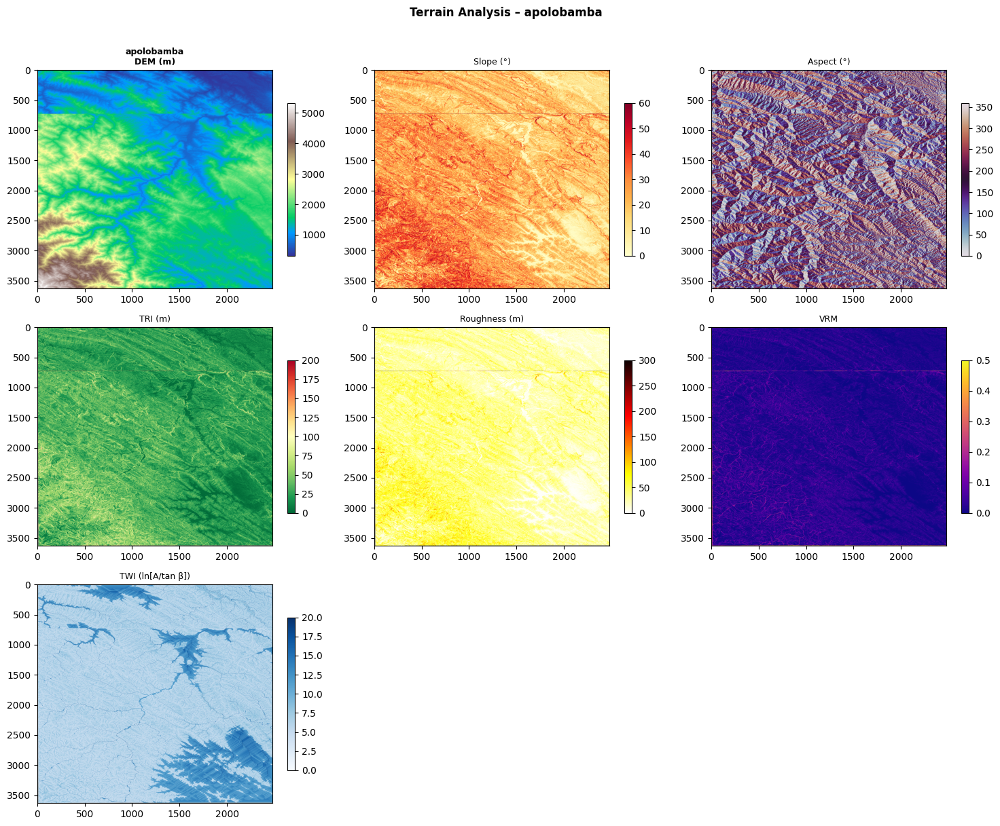

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_apolobamba.png


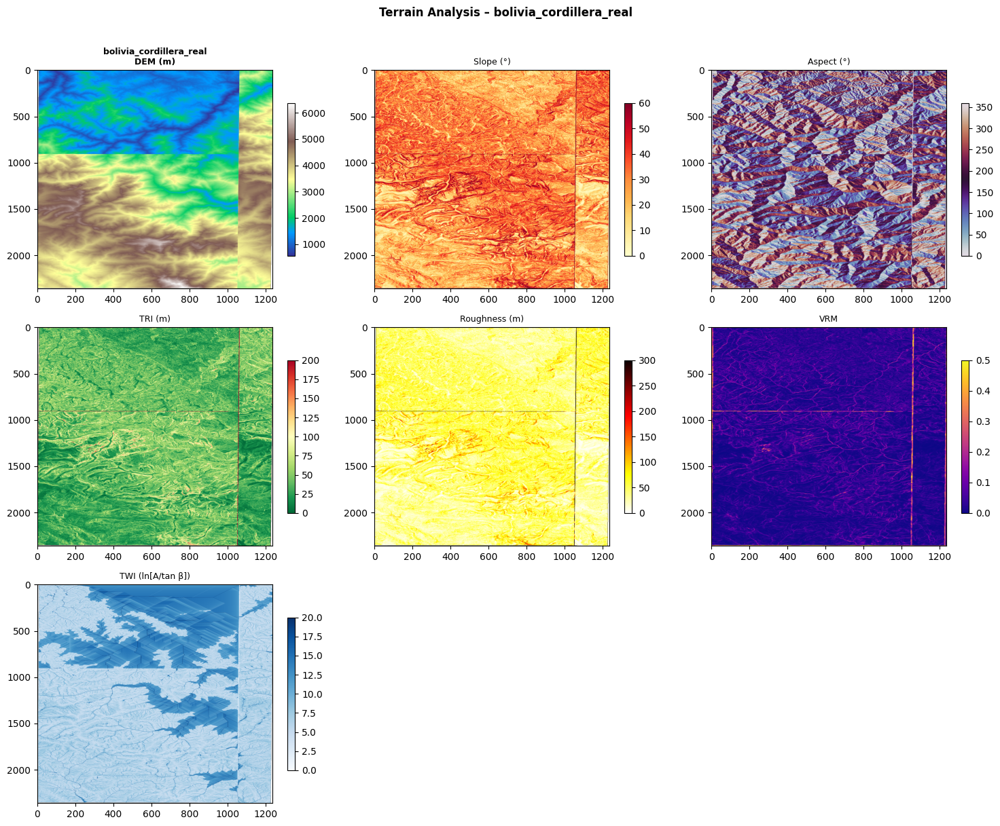

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_bolivia_cordillera_real.png


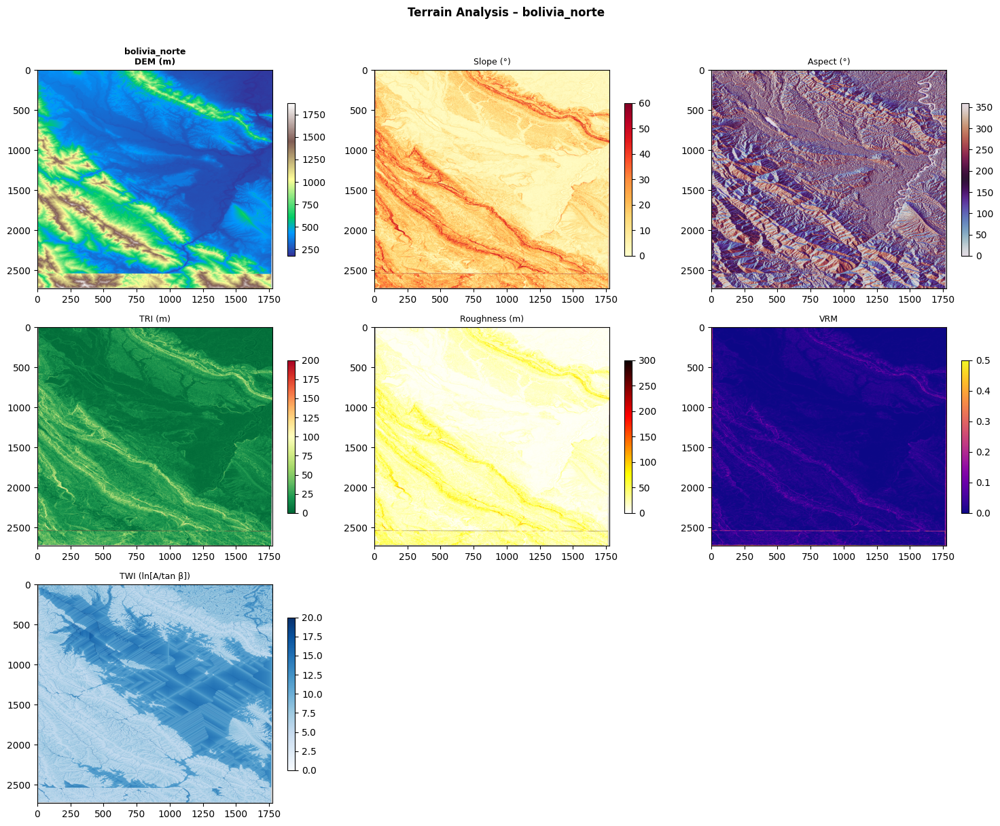

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_bolivia_norte.png


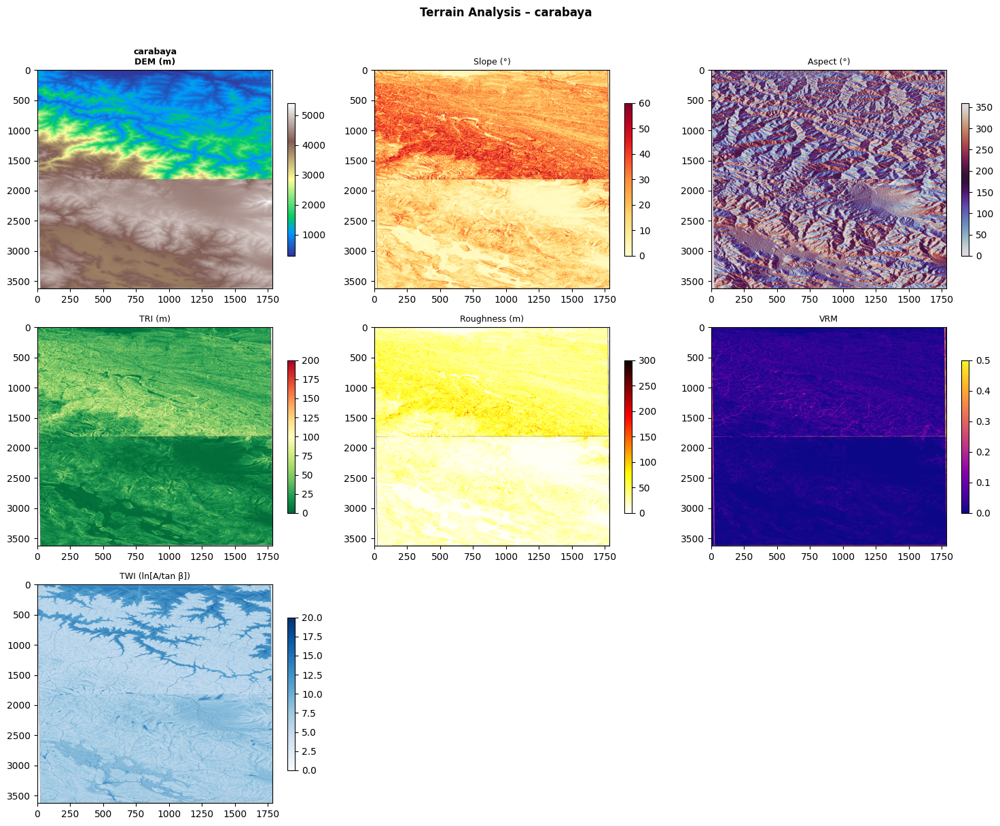

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_carabaya.png


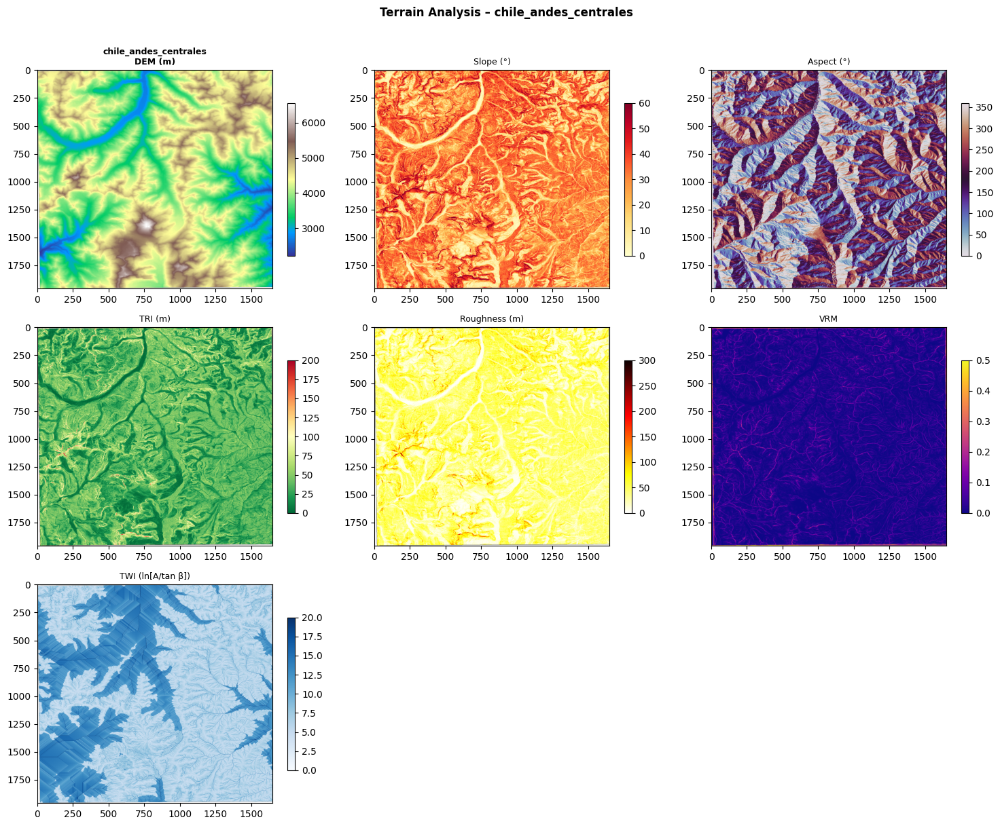

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_chile_andes_centrales.png


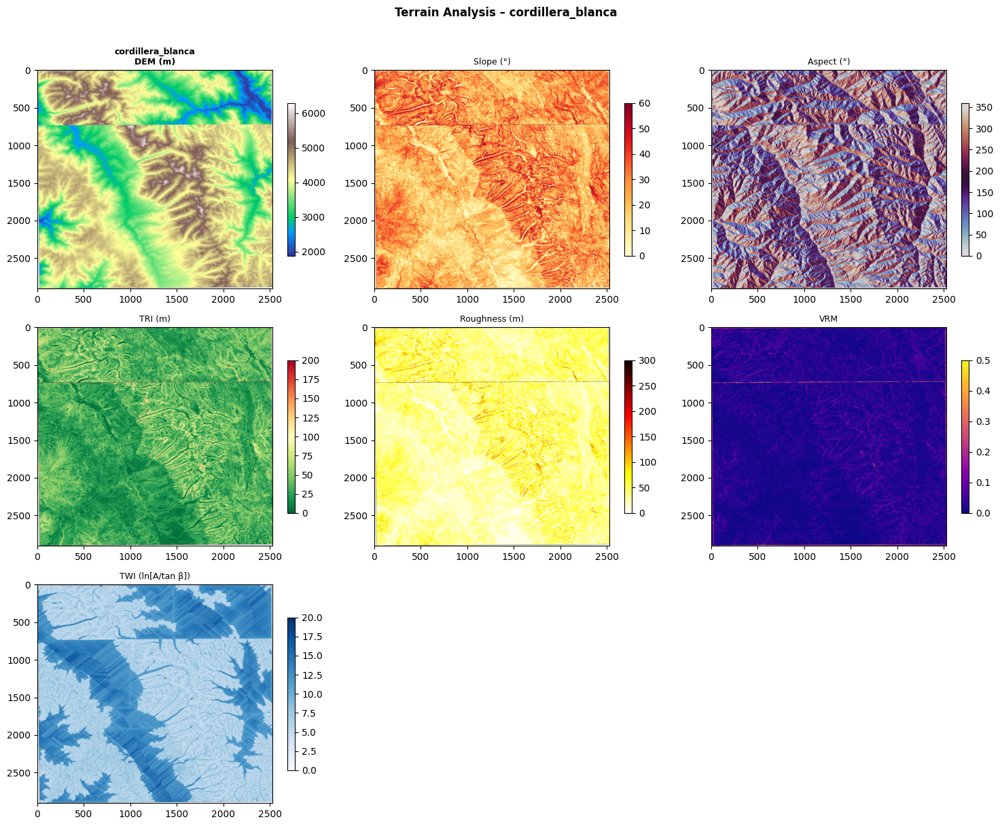

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_blanca.png


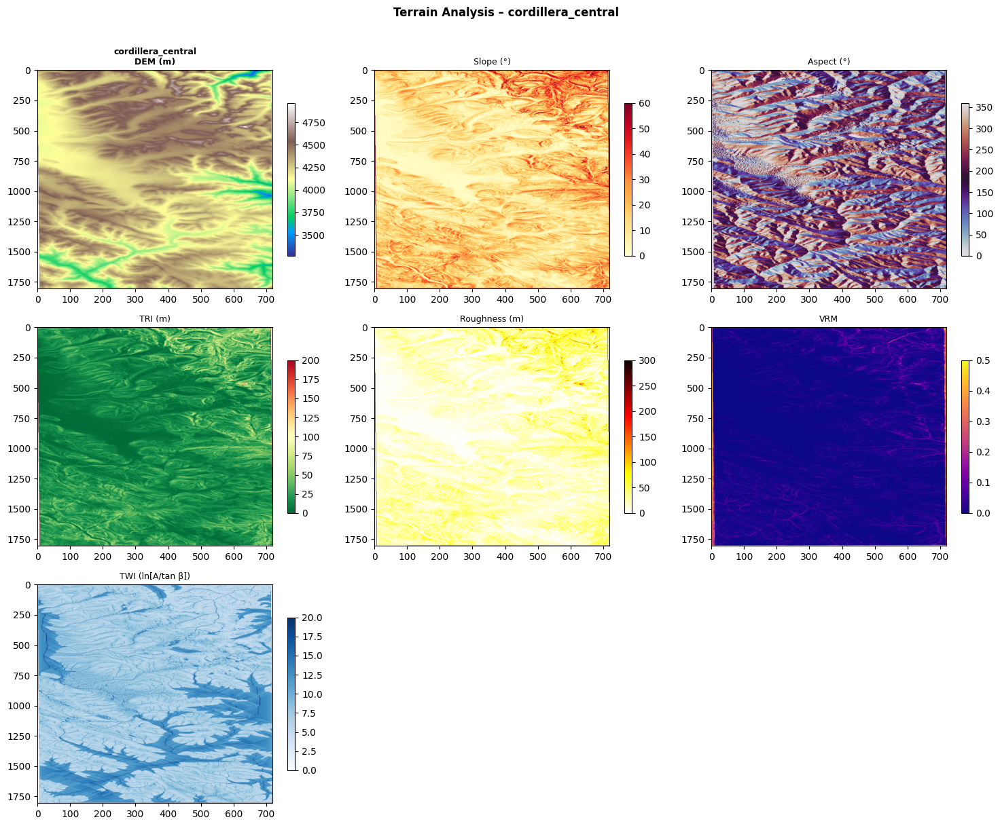

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_central.png


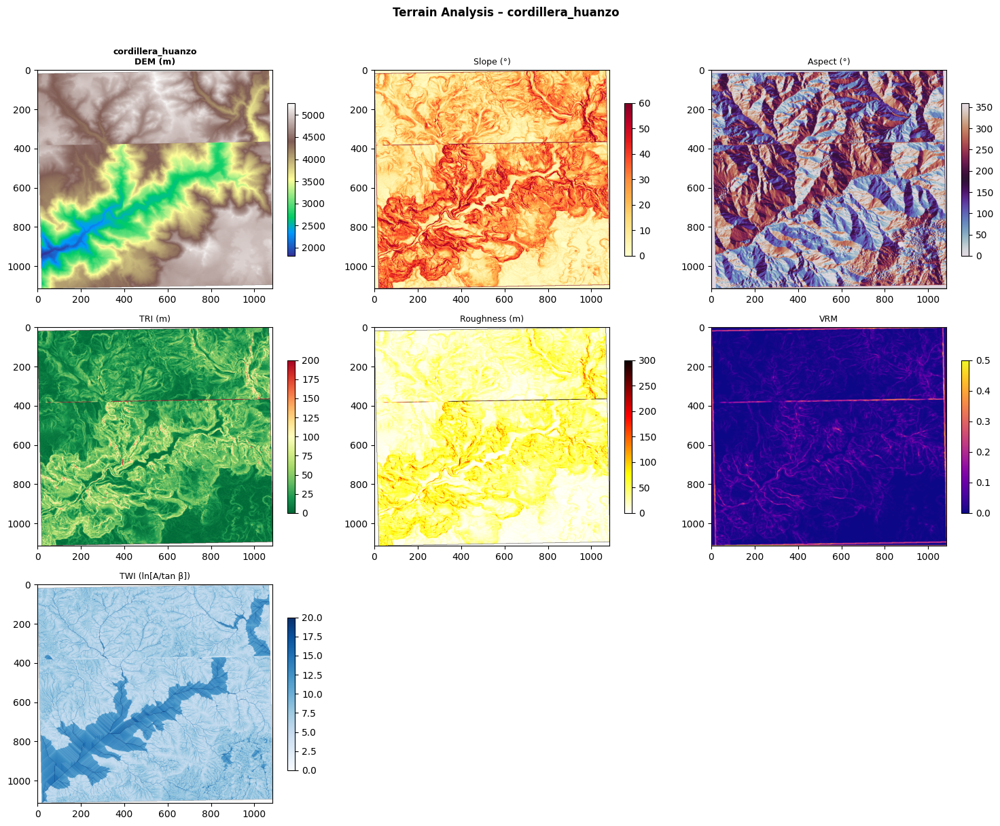

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_huanzo.png


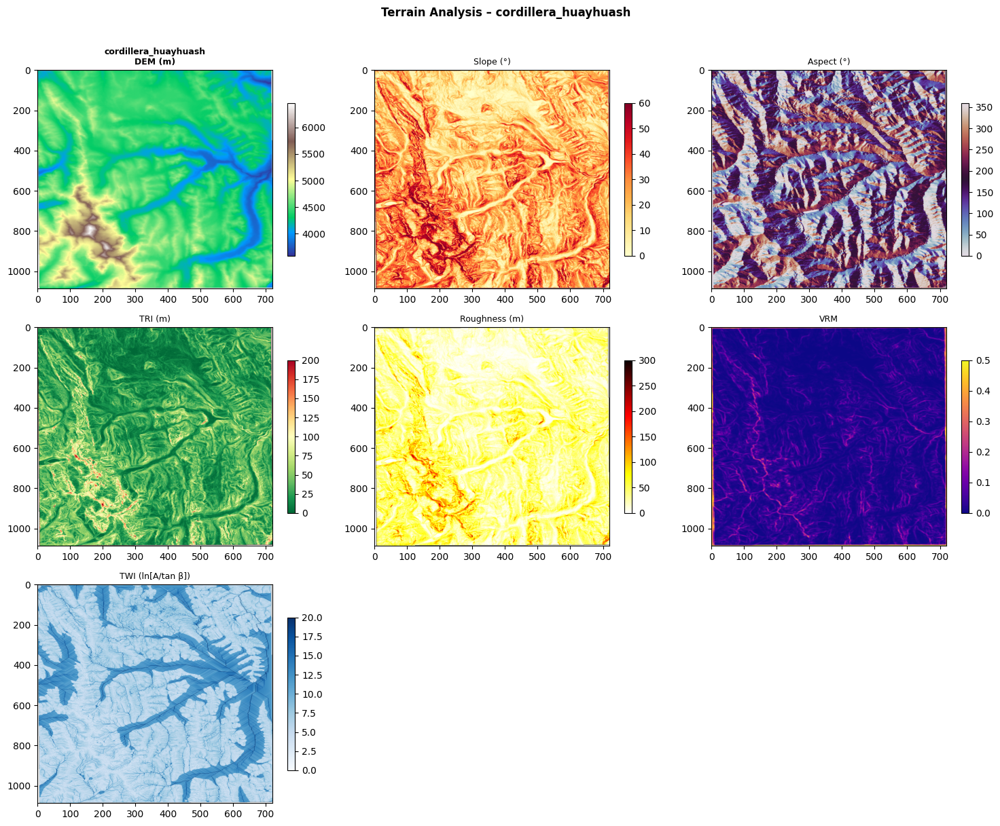

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_huayhuash.png


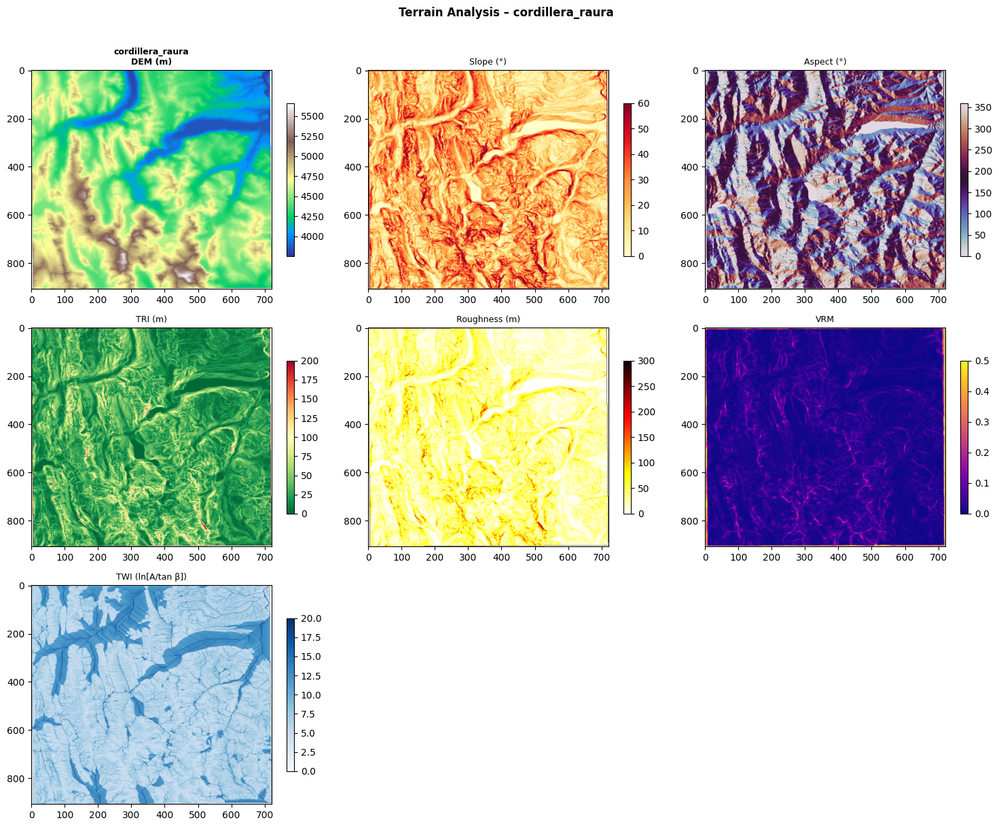

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_raura.png


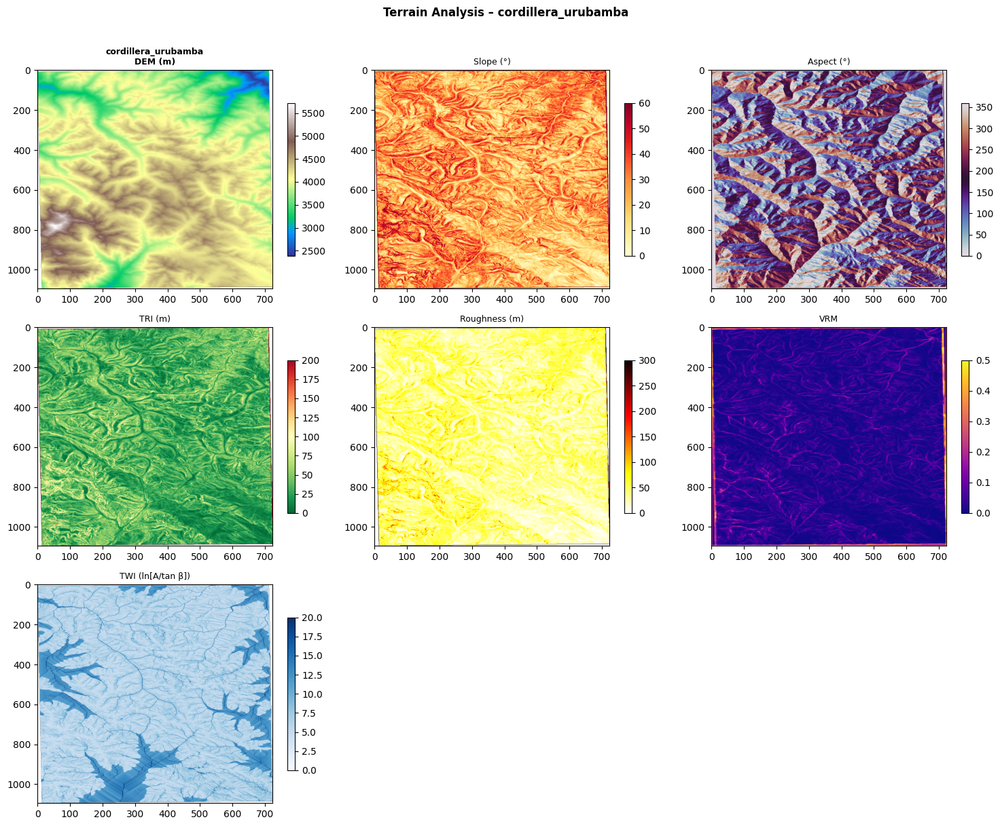

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_urubamba.png


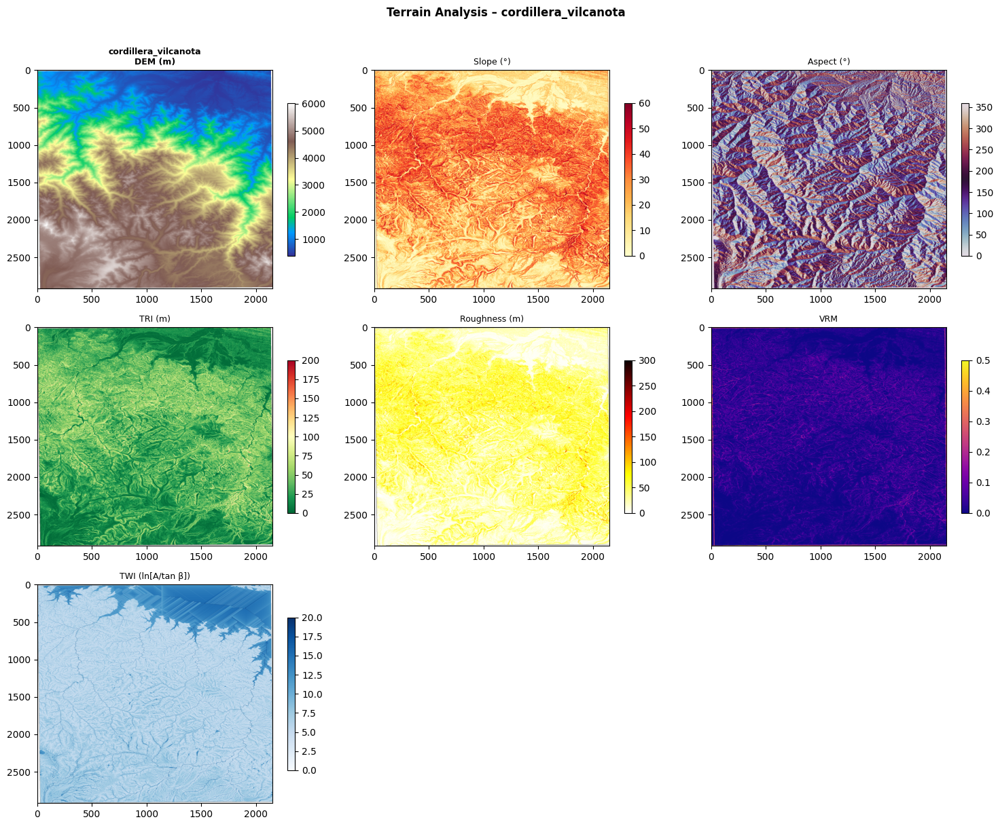

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_cordillera_vilcanota.png


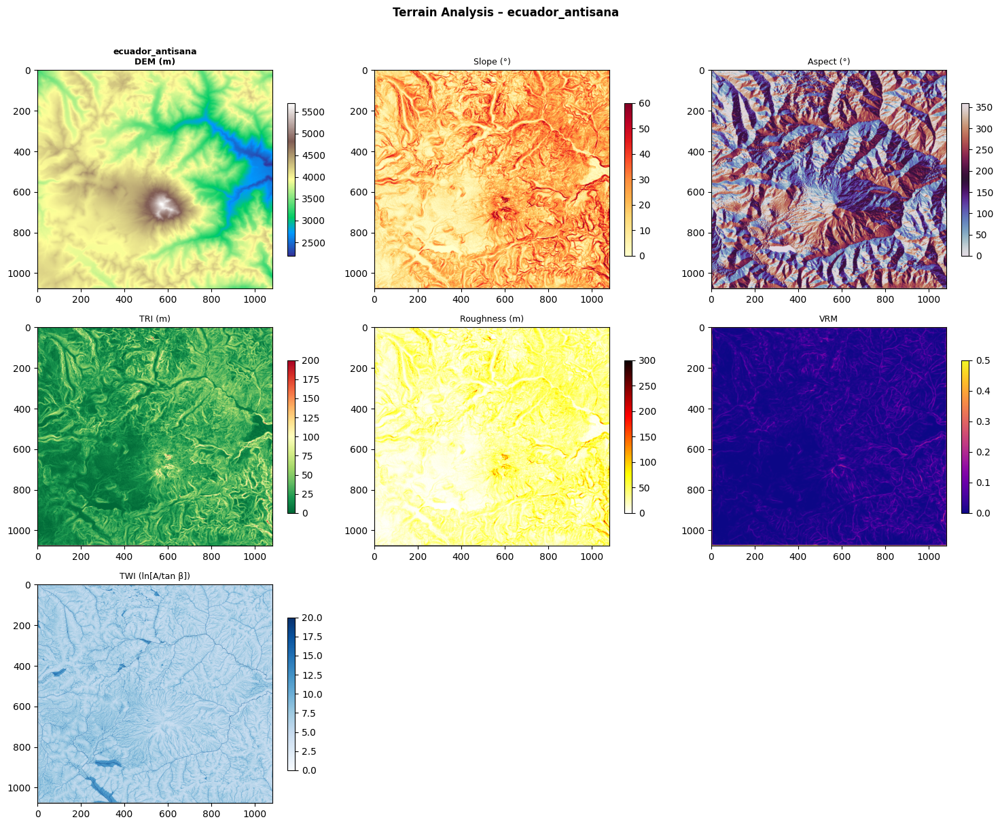

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_ecuador_antisana.png


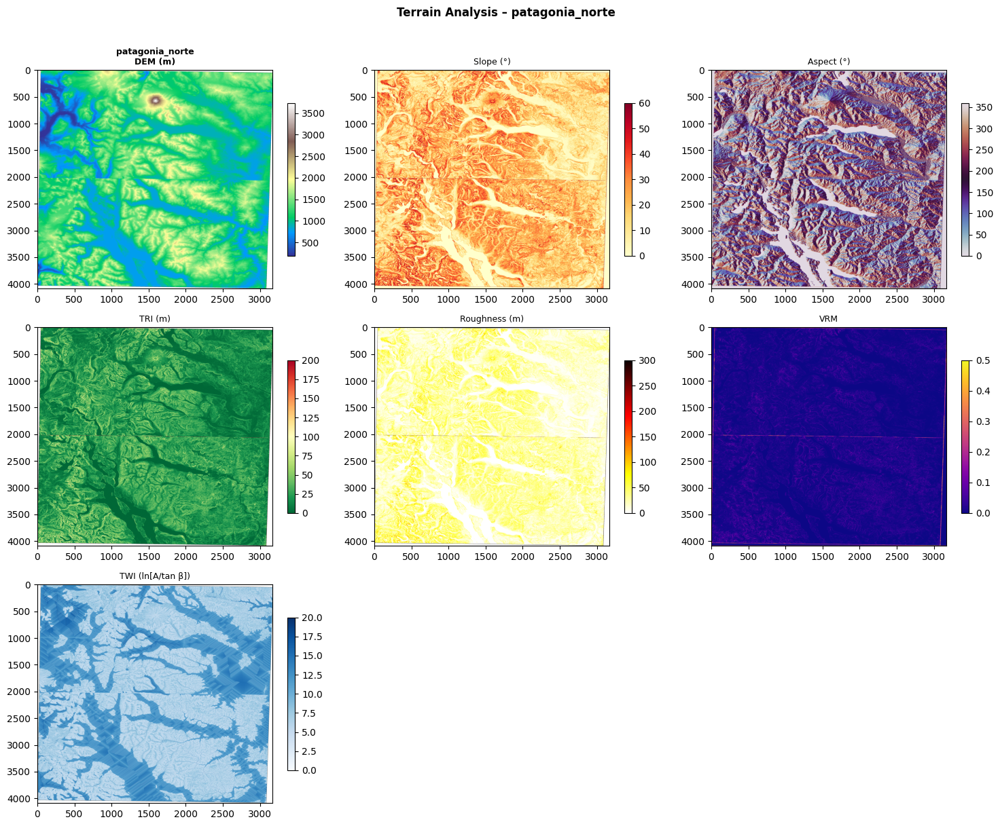

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_patagonia_norte.png


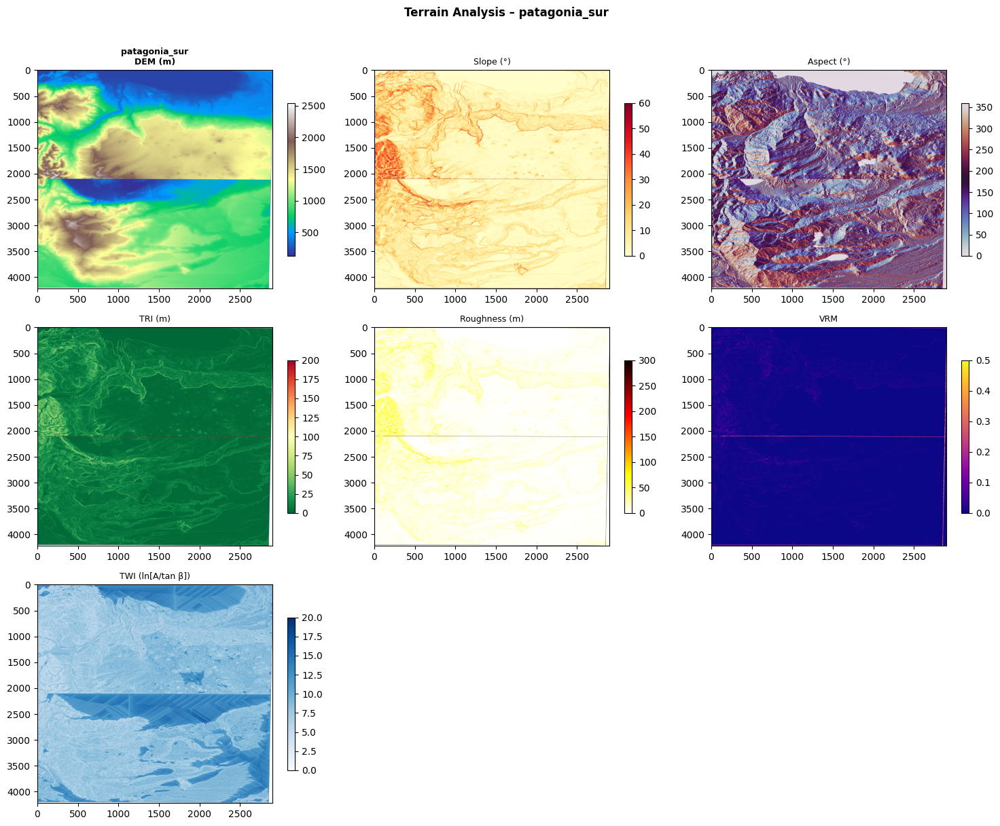

  Figure saved: D:\Research-Dev\AUP_Articulos_Inves\GLOF_Andes_Project-Paper\figures\terrain\terrain_patagonia_sur.png

Visualization complete.


In [10]:
# =============================================================================
# VISUALIZE – one representative area per figure
# =============================================================================
fig_dir = project_root / 'figures' / 'terrain'
fig_dir.mkdir(parents=True, exist_ok=True)

PRODUCTS = [
    ('slope',     'Slope (°)',              'YlOrRd',    0,    60),
    ('aspect',    'Aspect (°)',             'twilight',  0,   360),
    ('tri',       'TRI (m)',                'RdYlGn_r',  0,   200),
    ('roughness', 'Roughness (m)',          'hot_r',     0,   300),
    ('vrm',       'VRM',                    'plasma',    0,   0.5),
    ('twi',       'TWI (ln[A/tan β])',      'Blues',     0,    20),
]

for area in list(dem_utm_paths.keys()):  # visualise all 10 study areas
    out_dir = INTERIM_DIR / 'terrain' / area
    dem_path = dem_interim_dir / f'{area}_dem_utm.tif'

    available = [(p, lbl, cm, vmin, vmax)
                 for p, lbl, cm, vmin, vmax in PRODUCTS
                 if (out_dir / f'{p}.tif').exists()]

    if not available:
        continue

    ncols = 3
    nrows = (len(available) + ncols - 1) // ncols + 1  # +1 row for DEM
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    # DEM
    with rasterio.open(dem_path) as src:
        dem_data = src.read(1).astype(np.float32)
        dem_data[dem_data == src.nodata] = np.nan
    im = axes[0].imshow(dem_data, cmap='terrain', aspect='auto')
    axes[0].set_title(f'{area}\nDEM (m)', fontweight='bold', fontsize=9)
    plt.colorbar(im, ax=axes[0], shrink=0.7)

    for idx, (prod, lbl, cmap, vmin, vmax) in enumerate(available, start=1):
        with rasterio.open(out_dir / f'{prod}.tif') as src:
            data = src.read(1).astype(np.float32)
            data[data == src.nodata] = np.nan
        im = axes[idx].imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
        axes[idx].set_title(lbl, fontsize=9)
        plt.colorbar(im, ax=axes[idx], shrink=0.7)

    # Hide unused axes
    for ax in axes[len(available)+1:]:
        ax.set_visible(False)

    plt.suptitle(f'Terrain Analysis – {area}', fontsize=12, fontweight='bold', y=1.01)
    plt.tight_layout()

    fig_path = fig_dir / f'terrain_{area}.png'
    plt.savefig(fig_path, dpi=120, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f"  Figure saved: {fig_path}")

print("\nVisualization complete.")

## 6. Final Validation

In [11]:
# =============================================================================
# VALIDATE ALL OUTPUTS
# =============================================================================
print("=" * 70)
print("OUTPUT VALIDATION")
print("=" * 70)

products_required = ['slope', 'aspect', 'curvature', 'tri', 'roughness', 'vrm', 'twi']
all_ok = True

for area in OK_AREAS:
    dem_utm = dem_interim_dir / f'{area}_dem_utm.tif'
    terrain_dir = INTERIM_DIR / 'terrain' / area

    missing = []
    if not dem_utm.exists():
        missing.append('dem_utm')
    for p in products_required:
        if not (terrain_dir / f'{p}.tif').exists():
            missing.append(p)

    if missing:
        print(f"  [FAIL] {area}: missing {missing}")
        all_ok = False
    else:
        size_mb = sum((terrain_dir / f'{p}.tif').stat().st_size
                      for p in products_required) / 1_048_576
        print(f"  [OK]   {area}: all {len(products_required)} terrain products present "
              f"({size_mb:.1f} MB)")

# Check summary CSV
csv_path = PROCESSED_DIR / 'terrain_summary.csv'
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print(f"\n  [OK]   terrain_summary.csv: {len(df)} areas")
else:
    print("\n  [FAIL] terrain_summary.csv not found")
    all_ok = False

print()
if all_ok:
    print("ALL OUTPUTS VALID — Ready for notebook 12_lake_detection.ipynb")
else:
    print("Some outputs are missing. Re-run with force=True or check errors above.")

OUTPUT VALIDATION
  [OK]   apolobamba: all 7 terrain products present (252.2 MB)
  [OK]   bolivia_cordillera_real: all 7 terrain products present (63.6 MB)
  [OK]   bolivia_norte: all 7 terrain products present (134.8 MB)
  [OK]   carabaya: all 7 terrain products present (171.4 MB)
  [OK]   chile_andes_centrales: all 7 terrain products present (84.9 MB)
  [OK]   cordillera_blanca: all 7 terrain products present (191.9 MB)
  [OK]   cordillera_central: all 7 terrain products present (32.8 MB)
  [OK]   cordillera_huanzo: all 7 terrain products present (31.8 MB)
  [OK]   cordillera_huayhuash: all 7 terrain products present (20.5 MB)
  [OK]   cordillera_raura: all 7 terrain products present (16.9 MB)
  [OK]   cordillera_urubamba: all 7 terrain products present (20.9 MB)
  [OK]   cordillera_vilcanota: all 7 terrain products present (169.1 MB)
  [OK]   ecuador_antisana: all 7 terrain products present (31.5 MB)
  [OK]   patagonia_norte: all 7 terrain products present (328.3 MB)
  [OK]   patago

## Summary

| Output | Location | Used by |
|--------|----------|---------|
| `{area}_dem_utm.tif` | `data/interim/dem/` | **nb 12** (lake elevation filter) |
| `slope.tif` | `data/interim/terrain/{area}/` | nb 13 (feature extraction) |
| `aspect.tif` | `data/interim/terrain/{area}/` | nb 13 |
| `curvature.tif` | `data/interim/terrain/{area}/` | nb 13 |
| `tri.tif` | `data/interim/terrain/{area}/` | nb 13, 16 (threshold analysis) |
| `roughness.tif` | `data/interim/terrain/{area}/` | nb 13 |
| `vrm.tif` | `data/interim/terrain/{area}/` | nb 13 |
| `twi.tif` | `data/interim/terrain/{area}/` | nb 13 |
| `terrain_summary.csv` | `data/processed/` | nb 18 (visualization) |

**Next:** Run [12_lake_detection.ipynb](12_lake_detection.ipynb)